Importações:

In [111]:
import numpy as np
import matplotlib.pyplot as plt

Parâmetros:

In [112]:
alturas = np.array([172, 180, 175, 168, 177, 174, 181, 169, 173, 176, 152, 211, 160], dtype=float)
sigma_dados = 0.5

mu_prior = 170.0
sigma_prior = 5.0

n_iteracoes = 2_000
burn_in = 500

sigma_proposta = 0.5
iniciais = [155.0, 165.0, 180.0, 190.0]

print(f'Numero de pessoas: {alturas.size}')
print(f'Media amostral: {alturas.mean():.2f} cm')
print(f'Prior para mu: Normal({mu_prior:.1f}, {sigma_prior:.1f}^2)')
print(f'Iteracoes por cadeia: {n_iteracoes}')
print(f'Burn-in descartado: {burn_in}')
print(f'Desvio-padrao da proposta: {sigma_proposta}')

Numero de pessoas: 13
Media amostral: 174.46 cm
Prior para mu: Normal(170.0, 5.0^2)
Iteracoes por cadeia: 2000
Burn-in descartado: 500
Desvio-padrao da proposta: 0.5


Verificações:

In [113]:
if alturas.size == 0 or not np.all(np.isfinite(alturas)):
    raise ValueError('As alturas devem conter ao menos um valor finito.')
if sigma_dados <= 0 or sigma_prior <= 0:
    raise ValueError('Os desvios-padrao devem ser positivos.')
if n_iteracoes <= burn_in or sigma_proposta <= 0:
    raise ValueError('Use n_iteracoes maior que burn_in e sigma_proposta positivo.')

Executando Metropoles Hasting:

In [114]:
cadeias = []
taxas_aceitacao = []

for indice_cadeia, mu_inicial in enumerate(iniciais):
    rng = np.random.default_rng(42 + indice_cadeia)
    cadeia = np.empty(n_iteracoes)
    mu_atual = mu_inicial
    aceitos = 0

    # Cálculo da Log-posterior para mu_inicial (vamos calcular atraves do MCMC posteriormente para varios pontos)
    log_likelihood_atual = np.sum(
        -np.log(sigma_dados * np.sqrt(2 * np.pi))
        - 0.5 * ((alturas - mu_atual) / sigma_dados) ** 2
    )
    log_prior_atual = (
        -np.log(sigma_prior * np.sqrt(2 * np.pi))
        - 0.5 * ((mu_atual - mu_prior) / sigma_prior) ** 2
    )
    log_posterior_atual = log_likelihood_atual + log_prior_atual

    for t in range(n_iteracoes):
        # 1. Propor um vizinho do estado atual.
        mu_proposto = rng.normal(mu_atual, sigma_proposta)

        # 2. Calcular a log-posterior do candidato.
        log_likelihood_proposta = np.sum(
            -np.log(sigma_dados * np.sqrt(2 * np.pi))
            - 0.5 * ((alturas - mu_proposto) / sigma_dados) ** 2
        )
        log_prior_proposta = (
            -np.log(sigma_prior * np.sqrt(2 * np.pi))
            - 0.5 * ((mu_proposto - mu_prior) / sigma_prior) ** 2
        )
        log_posterior_proposta = log_likelihood_proposta + log_prior_proposta

        # 3. Aceitar ou rejeitar. log_alpha nunca e maior que zero.
        log_alpha = min(0.0, log_posterior_proposta - log_posterior_atual)
        if np.log(rng.uniform()) < log_alpha:
            mu_atual = mu_proposto
            log_posterior_atual = log_posterior_proposta
            aceitos += 1

        # 4. Guardar o estado, inclusive quando a proposta foi rejeitada.
        cadeia[t] = mu_atual

    cadeias.append(cadeia)
    taxas_aceitacao.append(aceitos / n_iteracoes)

cadeias = np.asarray(cadeias)
print(f'Taxas de aceitacao: {np.round(taxas_aceitacao, 3)}')

Taxas de aceitacao: [0.343 0.324 0.325 0.341]


Visualizando resultados:

In [115]:
amostras_por_cadeia = cadeias[:, burn_in:]
amostras_posteriores = amostras_por_cadeia.ravel()
media_posterior = amostras_posteriores.mean()
dp_posterior = amostras_posteriores.std(ddof=1)

print(f'Media posterior: {media_posterior:.2f} cm')
print(f'Desvio-padrao posterior: {dp_posterior:.2f} cm')

Media posterior: 174.46 cm
Desvio-padrao posterior: 0.13 cm


In [116]:
def calcular_log_posterior(mu):
    log_likelihood = np.sum(
        -np.log(sigma_dados * np.sqrt(2 * np.pi))
        - 0.5 * ((alturas - mu) / sigma_dados) ** 2
    )

    log_prior = (
        -np.log(sigma_prior * np.sqrt(2 * np.pi))
        - 0.5 * ((mu - mu_prior) / sigma_prior) ** 2
    )

    return log_likelihood + log_prior


n_cadeias = len(cadeias)


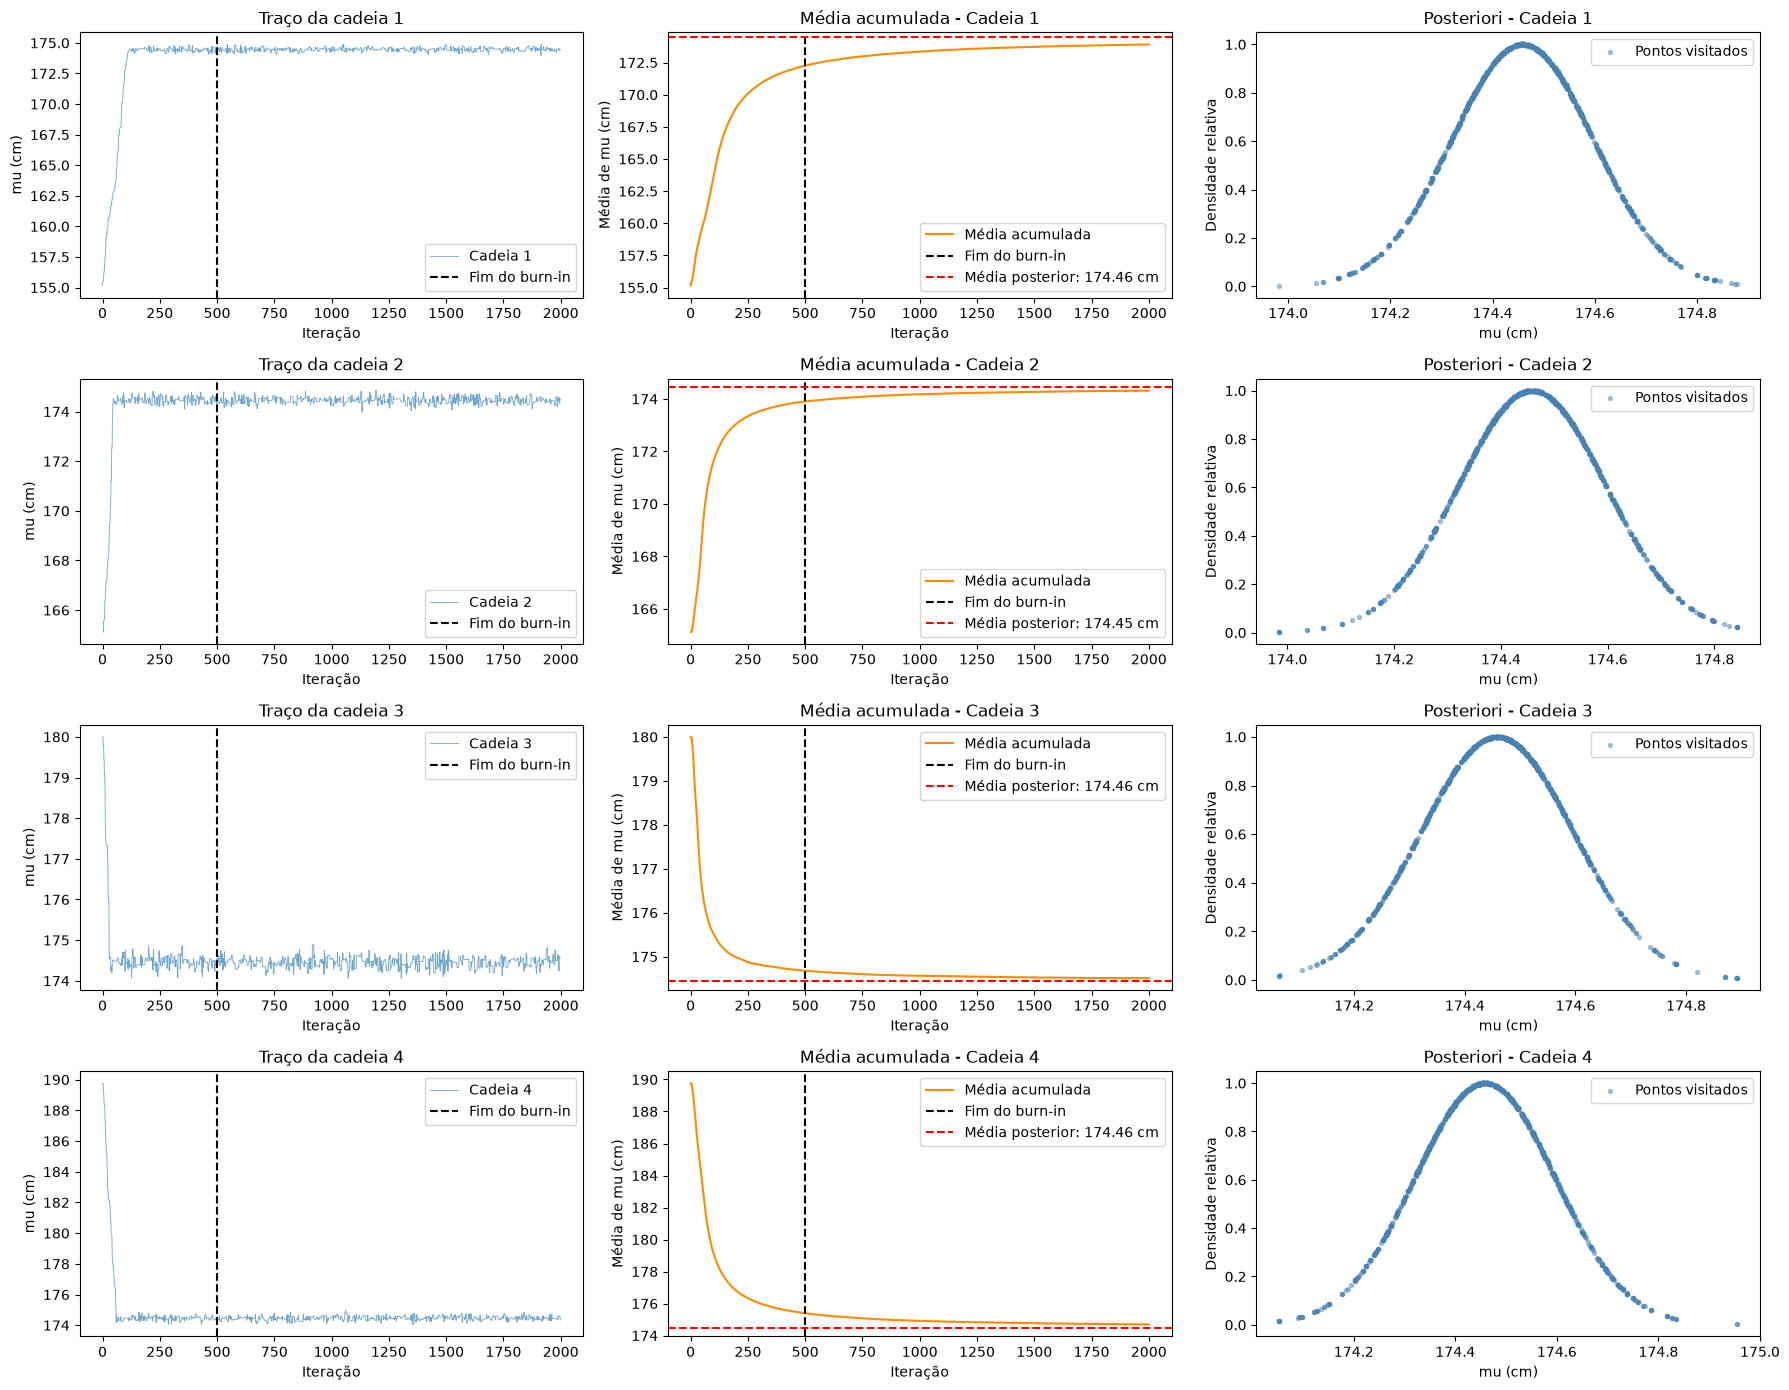

In [ ]:

fig, axes = plt.subplots(n_cadeias, 3, figsize=(18, 3.5 * n_cadeias), squeeze=False)

for i, cadeia in enumerate(cadeias):
    ax_trace = axes[i, 0]
    ax_media = axes[i, 1]
    ax_pdf = axes[i, 2]

    # =====================================
    # 1. Traço da cadeia
    # =====================================
    ax_trace.plot(cadeia, alpha=0.65, linewidth=0.6, label=f'Cadeia {i + 1}')
    ax_trace.axvline(burn_in, color='black', linestyle='--', label='Fim do burn-in')
    ax_trace.set(xlabel='Iteração', ylabel='mu (cm)', title=f'Traço da cadeia {i + 1}')
    ax_trace.legend()

    # =====================================
    # 2. Média acumulada ao longo das iterações
    # =====================================
    amostras = cadeia[burn_in:]
    media_acumulada = np.cumsum(cadeia) / np.arange(1, len(cadeia) + 1)
    iteracoes = np.arange(1, len(cadeia) + 1)

    ax_media.plot(iteracoes, media_acumulada, color='darkorange', linewidth=1.5, label='Média acumulada')
    ax_media.axvline(burn_in, color='black', linestyle='--', label='Fim do burn-in')
    ax_media.axhline(amostras.mean(), color='red', linestyle='--', label=f'Média posterior: {amostras.mean():.2f} cm')
    ax_media.set(xlabel='Iteração', ylabel='Média de mu (cm)', title=f'Média acumulada - Cadeia {i + 1}')
    ax_media.legend()

    # =====================================
    # 3. Posteriori nos pontos visitados
    # =====================================
    log_probs = np.array([calcular_log_posterior(mu) for mu in amostras])
    probs_relativas = np.exp(log_probs - log_probs.max())

    ax_pdf.scatter(amostras, probs_relativas, s=8, alpha=0.45, color='steelblue', label='Pontos visitados')
    ax_pdf.set(xlabel='mu (cm)', ylabel='Densidade relativa', title=f'Posteriori - Cadeia {i + 1}')
    ax_pdf.legend()

plt.tight_layout()
plt.show()
alturas = np.array([172, 180, 175, 168, 177, 174, 181, 169, 173, 176, 152, 211, 160], dtype=float)
sigma_dados = 0.5

mu_prior = 170.0
sigma_prior = 5.0

n_iteracoes = 2_000
burn_in = 500

sigma_proposta = 0.5
iniciais = [155.0, 165.0, 180.0, 190.0]